In [74]:
import os
import jax

from jax import numpy as np, random as jr

jax.config.update("jax_enable_x64", True)

import amigo
import dorito
import astropy

# from optim_funcs import sgd, adam
from dLux import utils as dlu

# visualisation
import matplotlib.pyplot as plt
import matplotlib as mpl
import ehtplot
import scienceplots

# import cmasher as cmr

# matplotlib parameters
plt.style.use(["science", "bright", "no-latex"])

plt.rcParams["image.cmap"] = "inferno"
plt.rcParams["font.family"] = "serif"
plt.rcParams["image.origin"] = "lower"
plt.rcParams["figure.dpi"] = 250
plt.rcParams["font.size"] = 8
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"

inferno = mpl.colormaps["inferno"]
inferno_k = mpl.colormaps["inferno"]
viridis = mpl.colormaps["viridis"]
seismic = mpl.colormaps["seismic"]
cividis = mpl.colormaps["cividis"]

inferno.set_bad("k", 0.5)
viridis.set_bad("k", 0.5)
seismic.set_bad("k", 0.5)
cividis.set_bad("k", 0.5)
inferno_k.set_bad("k")

textwidth = 514.99507  # pt
linewidth = 247.79752  # pt

textwidth /= 72.27  # inches
linewidth /= 72.27  # inches
print(textwidth)
print(linewidth)

7.125986854849869
3.428774318527743


In [2]:
# Setting data path
from socket import gethostname

print(f"host name: {gethostname()}")

if (
    gethostname() == "maxs-mbp-14.shared.sydney.edu.au"
    or gethostname() == "Maxs-MacBook-Pro-14.local"
    or gethostname() == "maxs-mbp-14.research.sydney.edu.au"
):
    data_dir = "/Volumes/research-data/PRJ-PAT/max/data/JWST/"
    cache_dir = "/Volumes/research-data/PRJ-PAT/max/data/amigo_cache"
    amigo_files_path = "/Volumes/research-data/PRJ-PAT/max/data/amigo_files/v_0.0.11"
    output_path = "/Users/mc/nt_outputs/local_retrain"
    save_path = "/Users/mc/code/dorito_notebooks/files/retrain_figs"

elif gethostname().startswith("max-"):
    data_dir = "/home/dgxuser/max/data/JWST/"
    cache_dir = "/home/dgxuser/max/data/amigo_cache"
    amigo_files_path = "/home/dgxuser/max/data/amigo_files/v_0.0.11"
    output_path = "/home/dgxuser/max/outputs/retrain"

else:
    data_dir = "/fred/oz440/max/data/JWST/"
    cache_dir = "/fred/oz440/max/data/amigo_cache"
    amigo_files_path = "/fred/oz440/max/data/amigo_files/v_0.0.11"
    output_path = "/fred/oz440/max/outputs/retrain"

host name: Maxs-MacBook-Pro-14.local


In [3]:
from retrain_fns import summarise_files
import importlib

resource_path = importlib.resources.files(amigo).joinpath("data/badpix.npy")

with importlib.resources.as_file(resource_path) as file_path:
    badpix = np.array(np.load(file_path), dtype=int)
badpix_bool = badpix.astype(
    bool
)  # use for boolean masking; badpix (int) is kept for FITS writing

# # Add extra bad pixels
# badpix = np.load(f"{cache_dir}/full_badpix.npy")
# # badpix = np.load(f"{cache_dir}/full_badpix.npy")
# badpix = np.array(badpix, dtype=int)


def add_badpix(file):
    file["BADPIX"].data = badpix
    if file[0].header["EXP_TYPE"] == "NIS_DARK":
        file["BADPIX"].data[25, 74] = 1
    # if file[0].header["PROGRAM"] == "04481" and file[0].header["FILTER"] == "F430M":
    #     file["BADPIX"].data[30, 40] = 1
    return file


def sort_files(files):
    """
    use_pos=True (default): partition each filter's matches by AMI dither
    position (POS1-4, from get_pos's source centroid), keeping only POS1/POS2
    -- correct for calibrator/validator/binary exposures, which really were
    taken at one of those on-sky dither positions.

    use_pos=False: skip the position split entirely and keep whatever's
    matched, up to n. Flats and darks are lab exposures taken with no science
    target and no on-sky dither at all, so get_pos's "centroid the brightest
    pixel and match to the nearest POS" is meaningless for them -- a flat's
    lamp-illumination centroid or a dark's read-noise peak can land anywhere,
    including POS3/POS4, which use_pos=True's pos1/pos2-only branches would
    then silently drop. Confirmed via debug prints on a real job: get_files
    found our one dark file every time; sort_files was discarding it because
    get_pos(dark) happened to return "POS4". Flats have only ever "worked" by
    the same lucky coincidence of centroiding near POS1/POS2, not because the
    position concept legitimately applies to them.
    """
    files.sort(
        key=lambda x: (
            x[0].header["PROGRAM"],
            x[0].header["FILTER"],
            x[0].header["PATT_NUM"],
        ),
        reverse=True,
    )
    filts = ["F480M", "F430M", "F380M"]
    these_files = {}

    for filt in filts:

        matched = [f for f in files if f[0].header["FILTER"] == filt]

        pos1 = [f for f in matched if get_pos(f) == "POS1"]
        pos2 = [f for f in matched if get_pos(f) == "POS2"]
        x = []
        for a, b in zip(pos1, pos2):
            x.extend([a, b])
        x.extend(pos1[len(pos2) :])
        x.extend(pos2[len(pos1) :])

        these_files[filt] = x

    files = [f for sub_f in these_files.values() for f in sub_f]
    return files

In [4]:
from astropy.io import fits
from amigo.misc import get_pos
from amigo.files import get_files

calpsf_files = []
calbin_files = []

print("CAL4481 - Anand Sivaramakrishnan")
program_path = os.path.join(data_dir, "4481/calslope/")
files = get_files(program_path, "nis_calslope", IS_PSF=True)
calpsf_files += files
calpsf_files = [add_badpix(file) for file in calpsf_files]
calpsf_files = sort_files(calpsf_files)
summarise_files(calpsf_files)

print()
print("CAL8330 - Benjamin Pope")
program_path = os.path.join(data_dir, "8330/calslope/")
files = get_files(program_path, "nis_calslope")
calbin_files += files
calbin_files = [file for file in calbin_files if file[0].header["NGROUPS"] > 3]
calbin_files = [add_badpix(file) for file in calbin_files]
calbin_files = sort_files(calbin_files)
summarise_files(calbin_files)

CAL4481 - Anand Sivaramakrishnan
   program    target filter dither      g/i        date                       PI   CAL
0     4481  HD-41094  F480M    1/5   30/760  05-05-2024  Sivaramakrishnan, Anand  True
1     4481  HD-41094  F480M    2/5   30/760  05-05-2024  Sivaramakrishnan, Anand  True
2     4481  HD-41094  F480M    3/5   30/760  05-05-2024  Sivaramakrishnan, Anand  True
3     4481  HD-41094  F480M    4/5   30/760  05-05-2024  Sivaramakrishnan, Anand  True
4     4481  HD-41094  F480M    5/5   30/760  05-05-2024  Sivaramakrishnan, Anand  True
5     4481  HD-41094  F380M    1/5  11/1060  05-05-2024  Sivaramakrishnan, Anand  True
6     4481  HD-41094  F380M    2/5  11/1060  05-05-2024  Sivaramakrishnan, Anand  True
7     4481  HD-41094  F380M    3/5  11/1060  05-05-2024  Sivaramakrishnan, Anand  True
8     4481  HD-41094  F380M    4/5  11/1060  05-05-2024  Sivaramakrishnan, Anand  True
9     4481  HD-41094  F380M    5/5  11/1060  05-05-2024  Sivaramakrishnan, Anand  True
10    4481

In [5]:
flat_files = []
print()
print("FLATS")
program_path = os.path.join(data_dir, "FLATS/calslope/")
files = get_files(program_path, "nis_calslope", EXP_TYPE="NIS_LAMP")
flat_files += files
# flat_files = [file for file in flat_files if file[0].header["NGROUPS"] != 45]
flat_files = sort_files(flat_files)

flat_files = [add_badpix(file) for file in flat_files]
flat_files = flat_files[0:2]
summarise_files(flat_files)


FLATS
  program   target filter dither    g/i        date             PI   CAL
0    1503  UNKNOWN  F480M    1/1  30/10  16-03-2023  Martel, Andre  FLAT
1    6654  UNKNOWN  F430M    1/1  30/10  27-07-2024  Martel, Andre  FLAT


In [6]:
dark_files = []
# print()
# print("DARKS")
# program_path = os.path.join(data_dir, "DARKS/calslope/")
# files = get_files(program_path, "nis_calslope", EXP_TYPE="NIS_DARK")
# dark_files += files
# dark_files = [file for file in dark_files if file[0].header["NGROUPS"] != 800]
# print(len(dark_files))
# dark_files = sort_files(dark_files)

# dark_files = [add_badpix(file) for file in dark_files]
# summarise_files(dark_files)

In [7]:
val_files = []

# Collated validator subset
program_path = os.path.join(data_dir, "VAL_SUBSET/calslope/")
files = get_files(program_path, "nis_calslope", IS_PSF=True)
files = sort_files(files)
val_files += files

# Adding bad pixels and summarising metadata
val_files = [add_badpix(file) for file in val_files]
summarise_files(val_files)

   program            target filter dither     g/i        date                 PI   CAL
0     1093          HD-36805  F480M    1/2    9/65  23-05-2022  Thatte, Deepashri  True
1     1093          HD-36805  F480M    2/2    9/65  23-05-2022  Thatte, Deepashri  True
2     1093          HD-36805  F430M    1/2    6/82  23-05-2022  Thatte, Deepashri  True
3     1093          HD-36805  F430M    2/2    6/82  23-05-2022  Thatte, Deepashri  True
4     1093          HD-36805  F380M    1/2   3/122  23-05-2022  Thatte, Deepashri  True
5     1093          HD-36805  F380M    2/2   3/122  23-05-2022  Thatte, Deepashri  True
6     1093          HD-36805  F480M    1/1    9/65  05-06-2022  Thatte, Deepashri  True
7     1093          HD-36805  F430M    1/1    6/82  05-06-2022  Thatte, Deepashri  True
8     1093          HD-36805  F380M    1/1   3/122  05-06-2022  Thatte, Deepashri  True
9     1093          HD-36805  F480M    1/1    9/65  05-06-2022  Thatte, Deepashri  True
10    1093          HD-36805  F4

In [8]:
# window_size = 13
# s = window_size // 2
# # Dark, distinct-hue lines: every level sits on the light olive/yellow end of cividis, where these clear 3:1
# contour_levels = {20000: "k", 30000: "#2b10e9", 40000: "#d00000"}

# for filt in ["F480M", "F430M", "F380M"]:
#     filt_psf = [f for f in calpsf_files if f[0].header["FILTER"] == filt]
#     filt_bin = [f for f in calbin_files if f[0].header["FILTER"] == filt]
#     rows = {
#         "4481": filt_psf,
#         "8330 POS1": [f for f in filt_bin if get_pos(f) == "POS1"],
#         "8330 POS2": [f for f in filt_bin if get_pos(f) == "POS2"],
#     }

#     # Cut out the window around the peak of each top group
#     windows = {}
#     for i, (label, row_files) in enumerate(rows.items()):
#         row_files = sorted(row_files, key=lambda f: f[0].header["PATT_NUM"])

#         for j, file in enumerate(row_files):
#             top_group = np.array(file["RAMP"].data[-1])
#             im = np.where(badpix, np.nan, top_group)

#             ix, iy = np.argwhere(im == np.nanmax(im))[0]
#             ix, iy = int(ix), int(iy)

#             windows[i, j] = (
#                 file[0].header["PATT_NUM"],
#                 im[ix - s : ix + s + 1, iy - s : iy + s + 1],
#             )

#     # One colour scale for the whole figure
#     all_vals = np.concatenate([w.ravel() for _, w in windows.values()])
#     norm = mpl.colors.PowerNorm(0.5, vmin=np.nanmin(all_vals), vmax=np.nanmax(all_vals))

#     fig, ax = plt.subplots(3, 5, figsize=(textwidth, 3), layout="compressed")
#     for a in ax.ravel():
#         a.axis("off")

#     for i, label in enumerate(rows):
#         ax[i, 0].text(
#             -0.15,
#             0.5,
#             label,
#             transform=ax[i, 0].transAxes,
#             rotation=90,
#             ha="right",
#             va="center",
#         )

#     for (i, j), (patt_num, im) in windows.items():
#         pcm = ax[i, j].imshow(im, cividis, norm=norm)
#         # ax[i, j].set(title=f"Dither {patt_num}")

#         # contour() warns when a level is outside the data range, so only draw those that are inside
#         for level, color in contour_levels.items():
#             if np.nanmax(im) > level:
#                 ax[i, j].contour(
#                     np.asarray(im), levels=[level], colors=color, linewidths=0.8
#                 )

#     cbar = fig.colorbar(pcm, ax=ax, fraction=0.03, pad=0.02, label="DN")
#     for level, color in contour_levels.items():
#         if level < norm.vmax:
#             cbar.ax.axhline(level, color=color, linewidth=1)
#     fig.suptitle(filt)
#     plt.show()

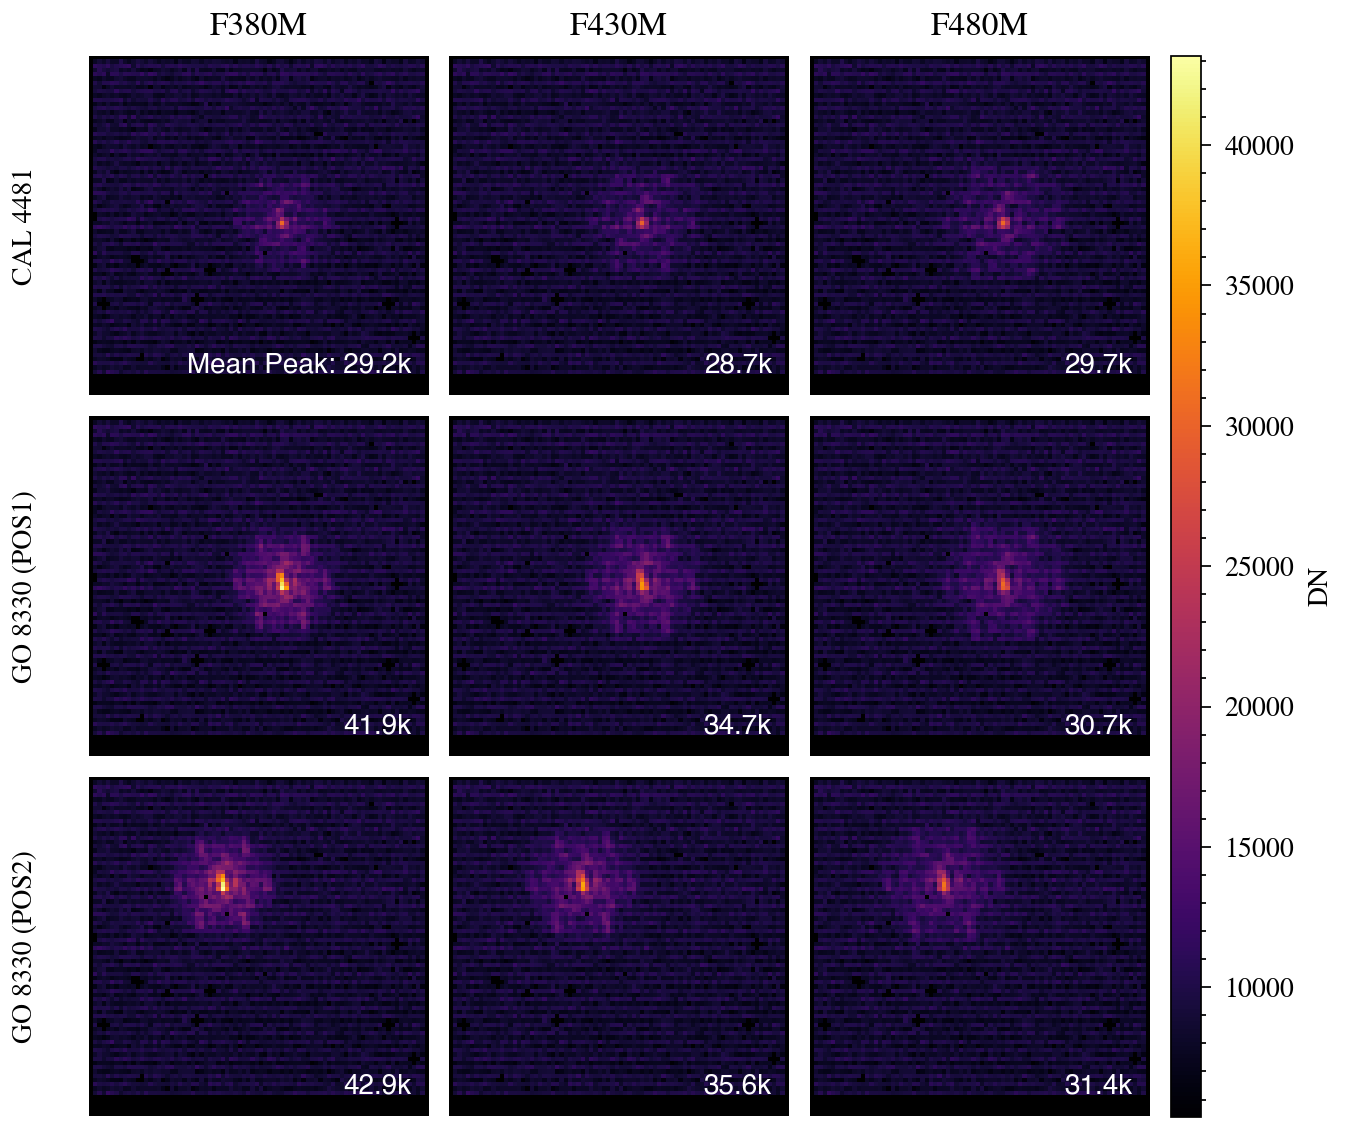

In [9]:
# Summary: first dither of each program, one column per filter (reuses s and contour_levels from the cell above)
filts = ["F380M", "F430M", "F480M"]
rows = {
    "CAL 4481": calpsf_files,
    "GO 8330 (POS1)": [f for f in calbin_files if get_pos(f) == "POS1"],
    "GO 8330 (POS2)": [f for f in calbin_files if get_pos(f) == "POS2"],
}

# Cut out the window around the peak of each top group
windows = {}
peaks = {}
for i, (label, row_files) in enumerate(rows.items()):
    for j, filt in enumerate(filts):
        dithers = [f for f in row_files if f[0].header["FILTER"] == filt]
        file = min(dithers, key=lambda f: f[0].header["PATT_NUM"])
        top_group = np.array(file["RAMP"].data[-1])
        im = np.where(badpix, np.nan, top_group)

        ix, iy = np.argwhere(im == np.nanmax(im))[0]
        ix, iy = int(ix), int(iy)

        windows[i, j] = im

        # Peak of the top group, averaged over every dither this panel stands in for
        peaks[i, j] = np.mean(
            np.array(
                [
                    np.nanmax(np.where(badpix, np.nan, np.array(f["RAMP"].data[-1])))
                    for f in dithers
                ]
            )
        )

# One colour scale for the whole figure
all_vals = np.concatenate([w.ravel() for w in windows.values()])
norm = mpl.colors.PowerNorm(1, vmin=np.nanmin(all_vals), vmax=np.nanmax(all_vals))

fig, ax = plt.subplots(
    3,
    3,
    figsize=(textwidth, 4.5),
    layout="compressed",
    # gridspec_kw={"wspace": 0.01, "hspace": 0.01},
)
for a in ax.ravel():
    a.axis("off")

for j, filt in enumerate(filts):
    ax[0, j].set_title(filt)

for i, label in enumerate(rows):
    ax[i, 0].text(
        -0.15,
        0.5,
        label,
        transform=ax[i, 0].transAxes,
        rotation=90,
        ha="right",
        va="center",
    )

for (i, j), im in windows.items():
    pcm = ax[i, j].imshow(im, inferno_k, norm=norm)

    peak_text = f"{peaks[i, j] / 1e3:.1f}k"
    if (i, j) == (0, 0):
        peak_text = f"Mean Peak: {peak_text}"
    ax[i, j].text(
        1 - 0.05,
        1 - 0.95,
        peak_text,
        transform=ax[i, j].transAxes,
        fontfamily="Helvetica",
        color="white",
        ha="right",
        va="bottom",
    )

# aspect sets the bar's height:width ratio; the default (20) stops short of the full grid height here
cbar = fig.colorbar(pcm, ax=ax, fraction=0.03, pad=0.02, aspect=35, label="DN")
plt.savefig(os.path.join(save_path, "data.pdf"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(save_path, "data.png"), dpi=300, bbox_inches="tight")
plt.show()

In [10]:
cal_flag = True
binary_flag = True
val_flag = True
flat_flag = True
dark_flag = True

from amigo.model_fits import PointFit, FlatFit, DarkFit, BinaryFit


class UniqueAbPointFit(PointFit):
    def get_key(self, param):
        match param:
            case "aberrations":
                return "_".join((self.filter, self.key))
            case "defocus":
                return "_".join((self.program, self.filter, self.POS))
            # rotation of the PSF is per program (amigo's default) except for 01093, whose
            # validators come from two visits at different pupil-wheel positions
            case "rotations" if self.program == "01093":
                return "_".join((self.program, self.observation))
        return super().get_key(param)


# One wavefront per program, filter and dither position. 04481 is all POS1, so for the
# calibrators this only renames the key, matching the _POS1 keys trained in final_statev48.
class PosPointFit(PointFit):
    def get_key(self, param):
        if param in ["aberrations", "defocus"]:
            return "_".join((self.program, self.filter, self.POS))
        return super().get_key(param)


class PosBinaryFit(BinaryFit):
    def get_key(self, param):
        if param in ["aberrations", "defocus"]:
            return "_".join((self.program, self.filter, self.POS))
        return super().get_key(param)


class NoMigrationFlatFit(FlatFit):
    """A flat modelled without the network's charge migration (as the darks already are). The flats
    only see FF times whatever pattern the network makes, so with the network in them FF becomes
    whatever cancels it (flat_diag.py); without it, FF and non_linearity are set by the flats alone
    and no longer depend on the network weights."""

    def model_ramp(self, illuminance, model):
        from amigo.ramp_models import Ramp

        bias = self.calc_bias(illuminance, model)
        no_bleed = model.ramp_model.set("bleed", False)
        ramp = no_bleed.evolve_illuminance(illuminance.data, bias, self.ngroups)
        return Ramp(ramp, illuminance.pixel_scale)


# Construct the exposures
calpsf_exposures = [PosPointFit(file) for file in calpsf_files[0:3]] if cal_flag else []
calbin_exposures = (
    [PosBinaryFit(file) for file in calbin_files[0:3]] if binary_flag else []
)
val_exposures = [UniqueAbPointFit(file) for file in val_files[0:3]] if val_flag else []
flat_exposures = [NoMigrationFlatFit(file) for file in flat_files] if flat_flag else []
dark_exposures = [DarkFit(file) for file in dark_files] if dark_flag else []

cal_exposures = calpsf_exposures + calbin_exposures
exposures = cal_exposures + val_exposures + flat_exposures + dark_exposures
print(f"Total number of exposures: {len(exposures)}")

# just closing the files
files = calpsf_files + calbin_files + val_files + flat_files + dark_files
_ = [f.close() for f in files]

Total number of exposures: 11


In [11]:
from amigo.core_models import AmigoModel
from amigo.optical_models import AMIOptics
from amigo.detector_models import LinearDetector
from amigo.ramp_models import NonLinearRamp
from amigo.read_models import ReadModel
from amigo.vis_models import LogVisModel

load_dict = lambda x: np.load(f"{x}", allow_pickle=True).item()  # helper function


# Get the model
model = AmigoModel(
    exposures=cal_exposures[0:3],
    optics=AMIOptics(),
    detector=LinearDetector(),
    ramp_model=NonLinearRamp(),
    read=ReadModel(per_pixel_dark=True),
    vis_model=LogVisModel(load_dict(amigo_files_path + "/vis_basis.npy"), n_basis=420),
    # state=load_dict(amigo_files_path + "/calibration.npy"),
)

positions = model.positions
positions = jax.tree.map(lambda x: 0 * x, positions)
model = model.set("positions", positions)

In [12]:
model.positions

{'04481_001_02_03_3': Array([ 0., -0.], dtype=float64),
 '04481_001_02_03_4': Array([ 0., -0.], dtype=float64),
 '04481_001_02_03_5': Array([ 0., -0.], dtype=float64)}

In [78]:
D = model.optics.diameter

exp = cal_exposures[0]
psf = exp.model_psf(model).data
wfs = exp.model_wfs(model)
rad = dlu.arcsec2rad(model.optics.psf_pixel_scale / model.optics.oversample)
wfs_rad = wfs.set("pixel_scale", np.full_like(wfs.pixel_scale, rad))
otf = model.vis_model.wfs_to_otf(wfs_rad)

npix = 255
extent_m = 2 * D
pscale_uv = extent_m / npix
otf_hi = jax.vmap(lambda a, wl: dlu.MFT(a, wl, rad, npix, pscale_uv))(
    wfs.psf, wfs.wavelength
).mean(0)
ext = [-D, D, -D, D]

In [69]:
textwidth

6.0

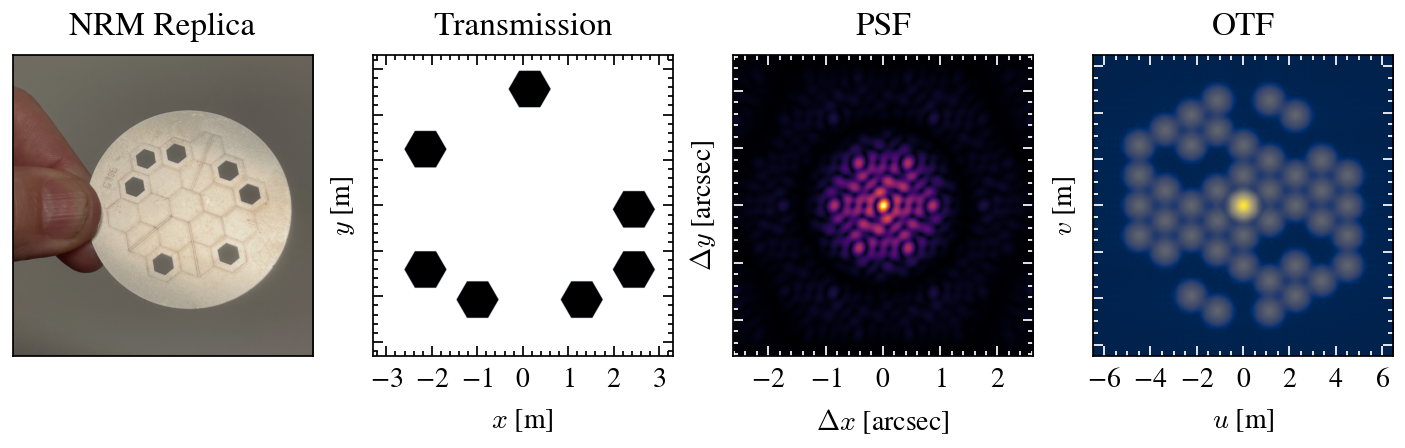

In [94]:
fig, ax = plt.subplots(1, 4, figsize=(textwidth, 1.75))

nrm_img = plt.imread(os.path.join(save_path, "NRM_srgb.png"))
ax[0].imshow(nrm_img, origin="upper")
ax[0].set(
    xticks=[],
    yticks=[],
    title="NRM Replica",
)

ext = [-D / 2, D / 2, -D / 2, D / 2]
ax[1].imshow(model.transmission, cmap="bone_ur", extent=ext)
ax[1].set_ylabel("$y$ [m]", labelpad=1)
ax[1].tick_params(labelleft=False)
ax[1].set(
    xticks=[-3, -2, -1, 0, 1, 2, 3],
    yticks=[-3, -2, -1, 0, 1, 2, 3],
    title="Transmission",
    xlabel="$x$ [m]",
)

# 1 0 PSF
psf_pscale = (
    model.optics.psf_pixel_scale / model.optics.oversample
)  # arcsec per oversampled pixel
half = psf.shape[0] * psf_pscale / 2
psf_ext = [-half, half, -half, half]

ax[2].imshow(psf, cmap=inferno, norm=mpl.colors.PowerNorm(0.5), extent=psf_ext)
ax[2].set_ylabel("$\\Delta y$ [arcsec]", labelpad=1)
ax[2].tick_params(labelleft=False)
ax[2].set(
    title="PSF",
    xticks=[-2, -1, 0, 1, 2],
    yticks=[-2, -1, 0, 1, 2],
    xlabel="$\\Delta x$ [arcsec]",
)
ax[2].tick_params(axis="both", which="both", colors="white", labelcolor="k")


# 1 1  OTF
u, v = model.vis_model.otf_coords
ext = [u.min(), u.max(), v.min(), v.max()]
ax[3].imshow(np.abs(otf_hi), cmap="cividis", norm=mpl.colors.PowerNorm(0.5), extent=ext)
ax[3].tick_params(axis="both", which="both", colors="white", labelcolor="k")
ax[3].tick_params(labelleft=False)

ax[3].set_ylabel("$v$ [m]", labelpad=1)
ax[3].set(
    title="OTF",
    xticks=[-6, -4, -2, 0, 2, 4, 6],
    yticks=[-6, -4, -2, 0, 2, 4, 6],
    xlabel="$u$ [m]",
)

# ax[3]
# for i in [0, 1]:
#     for j in [0, 1]:
#         ax[i][j].set(
#             xticks=[],
#             yticks=[],
#         )
#         # ax[i][j].axis("off")

plt.savefig(os.path.join(save_path, "mask.pdf"), dpi=300)
plt.savefig(os.path.join(save_path, "mask.png"), dpi=300)
plt.show()